
# Problem Statement:
**Cars24** is one of the leading used-car buying and selling platform in India.

#### Current methodology to estimate the selling price has three major components
1. Past records of the "Selling Prices" of the same _Make_ and _Model_
2. Rule based calculations for the depreciation of the car
2. Rule based calculation for condition of the vehicle

As the **Pricing Data Scientist working at Cars24, you are given a task**

### GOAL: To automate the process of estimating price of the used car



## Exploratory Data Analysis
###  If already installed pip, run below command
python -m pip install numpy pandas matplotlib seaborn scikit-learn

In [4]:
# Importing Libraries
import numpy as np
import pandas  as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Reading Data from CSV file
df = pd.read_csv("cars24.csv")

In [6]:
# displays the first 5 rows of a pandas DataFrame. It helps you quickly preview your dataset.
df.head()

,full_name,selling_price,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats
0,Maruti Alto Std,1.20,2012.0,Individual,120000,Petrol,Manual,19.70,796.0,46.30,5.0
1,Hyundai Grand i10 Asta,5.50,2016.0,Individual,20000,Petrol,Manual,18.90,1197.0,82.00,5.0
2,Hyundai i20 Asta,2.15,2010.0,Individual,60000,Petrol,Manual,17.00,1197.0,80.00,5.0
3,Maruti Alto K10 2010-2014 VXI,2.26,2012.0,Individual,37000,Petrol,Manual,20.92,998.0,67.10,5.0
4,Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV,5.70,2015.0,Dealer,30000,Diesel,Manual,22.77,1498.0,98.59,5.0


In [8]:
# full_name contains make and model, It will be better to seperate from full_name

In [11]:
# Getting the size of the data set i.e is how many columns and rows in data set
df.shape

(19980, 11)

In [13]:
# df.info() displays a summary of a pandas DataFrame, including:
# - Number of rows and columns
# - Column names
# - Number of non-null values in each column
# - Data types, such as int64, float64, and object
# - Memory usage

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19980 entries, 0 to 19979
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   full_name          19980 non-null  str    
 1   selling_price      19980 non-null  float64
 2   year               19980 non-null  float64
 3   seller_type        19980 non-null  str    
 4   km_driven          19980 non-null  int64  
 5   fuel_type          19980 non-null  str    
 6   transmission_type  19980 non-null  str    
 7   mileage            19980 non-null  float64
 8   engine             19980 non-null  float64
 9   max_power          19980 non-null  float64
 10  seats              19980 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.7 MB


In [14]:
# The DataFrame contains 19,980 rows and 11 columns, with no missing values.
#It includes 6 float64, 1 int64, and 4 string columns describing vehicle details and selling prices.
# The index ranges from 0 to 19,979, and memory usage is approximately 1.7 MB.

In [15]:
# display(df.describe()) shows a statistical summary of the numerical columns in your DataFrame as a formatted table in a Jupyter notebook.
# - df.describe() calculates the statistics.
#- display() displays the resulting table.

| Statistic | Meaning |
|---|---|
| **count** | Number of non-missing values |
| **mean** | Average value |
| **std** | Standard deviation—how spread out the values are |
| **min** | Smallest value |
| **25%** | First quartile—25% of values are at or below this point |
| **50%** | Median—the middle value |
| **75%** | Third quartile—75% of values are at or below this point |
| **max** | Largest value |

In [16]:
display(df.describe())

,selling_price,year,km_driven,mileage,engine,max_power,seats
count,19980.000000,19980.000000,1.998000e+04,19980.000000,19980.000000,19980.000000,19980.000000
mean,7.392066,2014.525125,5.824488e+04,19.347219,1476.327401,97.854443,5.317868
std,9.103088,3.249185,5.172509e+04,4.620053,520.449398,45.080670,0.835370
min,0.250000,1991.000000,1.000000e+02,0.000000,0.000000,5.000000,2.000000
25%,3.400000,2013.000000,3.116425e+04,16.800000,1197.000000,73.900000,5.000000
50%,5.200000,2015.000000,5.200000e+04,19.160000,1248.000000,86.700000,5.000000
75%,7.850000,2017.000000,7.400000e+04,22.320000,1582.000000,112.000000,5.000000
max,395.000000,2021.000000,3.800000e+06,120.000000,6752.000000,626.000000,14.000000


In [18]:
# include="all" tells pandas to summarize all columns, including numerical and string columns.
display(df.describe(include = 'all'))

,full_name,selling_price,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats
count,19980,19980.000000,19980.000000,19980,1.998000e+04,19980,19980,19980.000000,19980.000000,19980.000000,19980.000000
unique,3321,NaN,NaN,3,NaN,5,2,NaN,NaN,NaN,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,Dealer,NaN,Diesel,Manual,NaN,NaN,NaN,NaN
freq,210,NaN,NaN,11973,NaN,9817,16029,NaN,NaN,NaN,NaN
mean,NaN,7.392066,2014.525125,NaN,5.824488e+04,NaN,NaN,19.347219,1476.327401,97.854443,5.317868
std,NaN,9.103088,3.249185,NaN,5.172509e+04,NaN,NaN,4.620053,520.449398,45.080670,0.835370
min,NaN,0.250000,1991.000000,NaN,1.000000e+02,NaN,NaN,0.000000,0.000000,5.000000,2.000000
25%,NaN,3.400000,2013.000000,NaN,3.116425e+04,NaN,NaN,16.800000,1197.000000,73.900000,5.000000
50%,NaN,5.200000,2015.000000,NaN,5.200000e+04,NaN,NaN,19.160000,1248.000000,86.700000,5.000000
75%,NaN,7.850000,2017.000000,NaN,7.400000e+04,NaN,NaN,22.320000,1582.000000,112.000000,5.000000


In [20]:
# - `selling_price` ranges from [0.25, 395] - the values seem to be in lakhs.
# - `mileage` min is 0, max is 120 - need to check for outliers.
# - `engine` min is 0, max is 6752 - values appear to be in "cc" - cross check the  outliers.

# Distributions

<Axes: >

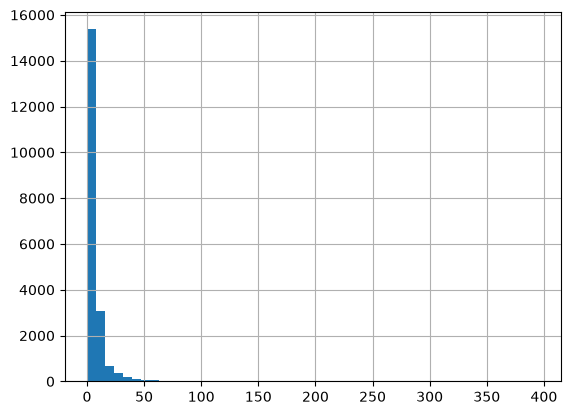

In [23]:
df['selling_price'].hist(bins = 50)

# Check the outliers

In [27]:
# Price over 100k
(df.loc[df.selling_price > 100].shape[0] / df.shape[0]) * 100
# df.selling_price > 100	Checks each row and returns True or False
# df.loc[df.selling_price > 100]	Selects only rows where the condition is True
# .shape[0]	Counts the selected rows
# df.shape[0]	Counts all rows in the DataFrame
# / ... * 100	Converts the fraction into a percentage

0.055055055055055056

In [30]:
# Lets saturate selling price at **100**.
df.loc[df.selling_price > 100, 'selling_price'] = 100

### Outliers and Missing Values

#### Q: Which plot(s) is/are suitable for outlier visualisation ?

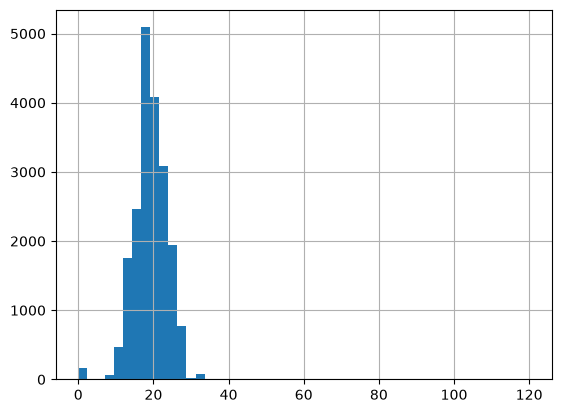

In [32]:
df["mileage"].hist(bins=50);
#Another useful plot is called the 'density' plot. Which is also similar to histogram, but with a more approximate shape. It tries to fit a suitable distribution over the histogram and hence includes points that might not even be present in data at hand.

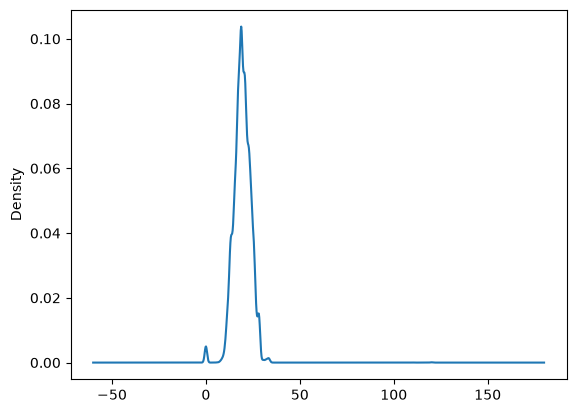

In [33]:
df["mileage"].plot.density();

We observe a skewed plot with right tail to long. An interesting point here would be mileage > 40, because after that it looks like the values mught just be outliers.
Above we saw that there was an unusual peak at 0. Lets investigate further. Looking at points where mileage is less than 5

In [34]:
df[df["mileage"]<=5].mileage.describe()

count    161.000000
mean       0.024845
std        0.315244
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        4.000000
Name: mileage, dtype: float64

Looks like we just have a number of points with mileage 0. That does not make much sense as it cannot be a real value for car mileage. Investigating mileage=0 cases

In [35]:
df.loc[df.mileage == 0].shape[0] / df.shape[0] # 0.8 %

0.008008008008008008

In [36]:
df[df["mileage"] == 0.0].shape

(160, 11)